# Assignment 2: Diabetes Classification

IE500618 - Group 13: Rune-André Gamlem, Magnus Grande, Ida Soldal

Dataset: `diabetes_binary_classification_data.csv`, referencing `Diabetes Classification - Understanding the Dataset`.

Workflow: UNDERSTAND -> EDA -> SPLIT -> PREPARE -> FIT -> PREDICT -> EVALUATE -> INTERPRET

### Setup

In [1]:
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
)

pd.set_option('display.max_columns', 100)

In [2]:
df = pd.read_csv('diabetes_binary_classification_data.csv')

In [3]:
# Feature groups by variable type, from the Understanding the Dataset guide
target = 'Diabetes_binary'
numerical = ['BMI', 'MentHlth', 'PhysHlth']
ordinal = ['GenHlth', 'Age', 'Education', 'Income']
binary = ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack',
          'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare',
          'NoDocbcCost', 'DiffWalk', 'Sex']

# What each ordinal code means, in code order 1, 2, 3, ... (from the guide), so plots and tables can show meanings instead of codes
labels = {
    'GenHlth': ['excellent', 'very good', 'good', 'fair', 'poor'],
    'Age': ['18-24', '25-29', '30-34', '35-39', '40-44', '45-49', '50-54', '55-59', '60-64', '65-69', '70-74', '75-79', '80+'],
    'Education': ['no school', 'grades 1-8', 'grades 9-11', 'high school grad', 'some college', 'college grad'],
    'Income': ['<10k', '10-15k', '15-20k', '20-25k', '25-35k', '35-50k', '50-75k', '75k+'],
}

## Step 1 - Understand the data

> - Identify the input features X and the target y.
> - Explain what class 0 and class 1 mean.
> - Check the number and proportion of observations in each class.
> - Choose three features of different types and briefly explain what their values mean. Use the Understanding the Dataset guide.

In [ ]:
# 1 - Input features X and target y

print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")  # guide: 253,680 rows and 22 columns
print(df.dtypes.value_counts())  # how many columns per data type
print(f"Missing values in total: {df.isna().sum().sum()}")  # the guide says there are none, but good practice to check anyway

X = df.drop(columns=[target])  # input features = the 21 survey variables
y = df[target].astype(int)  # target = diabetes status, stored as 0.0/1.0, turned into whole numbers so the classes print as 0 and 1

assert sorted(numerical + ordinal + binary) == sorted(X.columns)  # every feature is in exactly one type group, so none is forgotten in EDA or preprocessing
print(f"X: {X.shape[1]} features ({len(numerical)} numerical, {len(binary)} binary, {len(ordinal)} ordinal). y: {target}")

Shape: 253680 rows, 22 columns
float64    22
Name: count, dtype: int64
Missing values in total: 0
X: 21 features (3 numerical, 14 binary, 4 ordinal). y: Diabetes_binary


In [5]:
df.head()  # peek at what the actual data looks like

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


Every column is stored as `float64`, including the yes/no columns and the category codes. This is the same trap as `MS SubClass` in assignment 1: pandas sees numbers, but according to the guide only `BMI`, `MentHlth` and `PhysHlth` are numbers in the usual sense. The other 18 are categories that happen to be stored as numbers, which is why we wrote the type groups in the setup from the guide instead of from `dtypes`.

The guide also mentions that an older handout used a three-level coding of the target (0 = no diabetes, 1 = prediabetes, 2 = diabetes). Before relying on the guide's value ranges, we check them against what is actually in the file:

In [6]:
# Do the values in the CSV match the guide?

expected = {  # value range per column, according to the guide
    target: (0, 1), 'BMI': (12, 98), 'MentHlth': (0, 30), 'PhysHlth': (0, 30),
    'GenHlth': (1, 5), 'Age': (1, 13), 'Education': (1, 6), 'Income': (1, 8),
    **{col: (0, 1) for col in binary},
}
rows = []
for col, (low, high) in expected.items():
    rows.append({
        'column': col,
        'guide range': f"{low}-{high}",
        'min in CSV': df[col].min(),
        'max in CSV': df[col].max(),
        'distinct values': df[col].nunique(),
        'whole numbers only': (df[col] % 1 == 0).all(),  # codes and day counts should never have decimals
        'matches guide': df[col].min() == low and df[col].max() == high,
    })
pd.DataFrame(rows).set_index('column')

,guide range,min in CSV,max in CSV,distinct values,whole numbers only,matches guide
column,,,,,,
Diabetes_binary,0-1,0.0,1.0,2,True,True
BMI,12-98,12.0,98.0,84,True,True
MentHlth,0-30,0.0,30.0,31,True,True
PhysHlth,0-30,0.0,30.0,31,True,True
GenHlth,1-5,1.0,5.0,5,True,True
Age,1-13,1.0,13.0,13,True,True
Education,1-6,1.0,6.0,6,True,True
Income,1-8,1.0,8.0,8,True,True
HighBP,0-1,0.0,1.0,2,True,True


We see that every column matches the guide. The target only contains 0 and 1, so the binary description applies as expected, and the three-level coding does not. `BMI` is stored as whole numbers (84 distinct values), so it has been rounded somewhere before it reached us.

In [7]:
# 2 - Number and proportion of observations in each class

class_counts = pd.DataFrame({
    'count': y.value_counts(),
    'proportion': y.value_counts(normalize=True).round(3),
}).sort_index()
class_counts.index = ['0 = no diabetes', '1 = prediabetes or diabetes']  # meanings from the guide
print(class_counts)
print(f"\nAlways predicting class 0 would already be right {(y == 0).mean():.1%} of the time")  # the baseline we compare the model against in Step 6

                              count  proportion
0 = no diabetes              218334       0.861
1 = prediabetes or diabetes   35346       0.139

Always predicting class 0 would already be right 86.1% of the time


- **Class 0** = no diabetes, **class 1** = prediabetes **or** diabetes. The two are merged, so the model can never tell prediabetes apart from diabetes.
- The target is clearly **imbalanced**: `218,334` respondents (86.1%) are class 0 and `35,346` (13.9%) are class 1.

Why this matters: a model that always answers "no diabetes" is right 86.1% of the time without learning anything. Accuracy will therefore look high almost no matter what, so in Step 6 we compare against this baseline and look at precision and recall for class 1, the class we actually want to find. The imbalance is also why we stratify the split in Step 3.

### Duplicate rows

The guide says there may be identical rows and that we should keep them. We still want to know how many there are and what they look like before accepting that:

In [8]:
# Duplicate rows

duplicated = df.duplicated()  # True for every row that is an exact copy of an earlier row
print(f"Exact duplicate rows: {duplicated.sum()} ({duplicated.mean():.1%} of the data)")
print(f"Class 1 among all rows involved in duplicates: {df[df.duplicated(keep=False)][target].mean():.1%} (all rows: {df[target].mean():.1%})")

common = df.value_counts().head(3).reset_index()  # the three most common answer combinations, with how often each appears
common.T

Exact duplicate rows: 24206 (9.5% of the data)
Class 1 among all rows involved in duplicates: 1.3% (all rows: 13.9%)


,0,1,2
Diabetes_binary,0.0,0.0,0.0
HighBP,0.0,0.0,0.0
HighChol,0.0,0.0,0.0
CholCheck,1.0,1.0,1.0
BMI,21.0,23.0,23.0
Smoker,0.0,0.0,0.0
Stroke,0.0,0.0,0.0
HeartDiseaseorAttack,0.0,0.0,0.0
PhysActivity,1.0,1.0,1.0
Fruits,1.0,1.0,1.0


There are `24,206` duplicate rows (9.5%), and almost all of them are class 0 (1.3% class 1). The most common combination appears 59 times: a woman with no high blood pressure, no high cholesterol, BMI 21, physically active, eats fruit and vegetables, excellent health, 0 bad days, age 45-49, college graduate, income above $75k. With 14 yes/no answers and a handful of codes, many different healthy people will give exactly that set of answers, and there is no respondent ID that could show they are the same person.

Decision: keep the duplicates, as the guide says. Removing them would mainly remove healthy class 0 respondents and make the data less like the real survey.

### Three features of different types

| Feature | Type | Values | What a value means |
|---|---|---|---|
| `BMI` | Numerical (measurement) | 12-98 | A measured body mass index. `BMI = 30` is a BMI of 30. Distances are real: 35 is 5 units more than 30, and the step from 25 to 30 is the same size as from 30 to 35. |
| `HighBP` | Binary categorical | 0 / 1 | `1` = the respondent has high blood pressure, `0` = no. The 1 is a label, not an amount. Its mean (0.429) is the share of respondents answering yes. |
| `Age` | Ordinal categorical | 1-13 | An age **group**, not an age. `Age = 9` means 60-64 years old, not 9. The groups are ordered, but not equally wide: most cover 5 years, `1` covers 7 years (18-24) and `13` is open-ended (80+). |

The other ordinal codes have their own traps: for `GenHlth` a **higher** code means **worse** health (1 = excellent, 5 = poor), while for `Income` and `Education` a higher code means more income or education. Reading the numbers in the CSV without the guide would get both the meaning and the direction wrong.

## Step 2 - Explore the data

> Use EDA to investigate all input features and their relationships with `Diabetes_binary`:
> - **numerical** features: distributions, compared between the two target classes;
> - **binary categorical** features: counts/proportions, and proportion of `Diabetes_binary` across the two categories;
> - **ordered categorical** features: how the distribution or proportion of `Diabetes_binary` changes across the ordered categories.
>
> For the results discussed in detail: state the question, show evidence, explain what you observe, and what the evidence allows you to conclude and what it does not. Association is not causation.

Because the classes are imbalanced, we compare **proportions** rather than counts throughout: class 1 has about one sixth as many rows as class 0, so raw counts would make almost any class 1 bar look small. The overall share of class 1 (13.9%) is drawn as a dashed reference line, so a category above the line has more class 1 than average and one below it has less.

Following the guide, we do not compute ordinary correlations on the category codes. For categorical features we compare the share of class 1 across categories instead.

### Numerical features

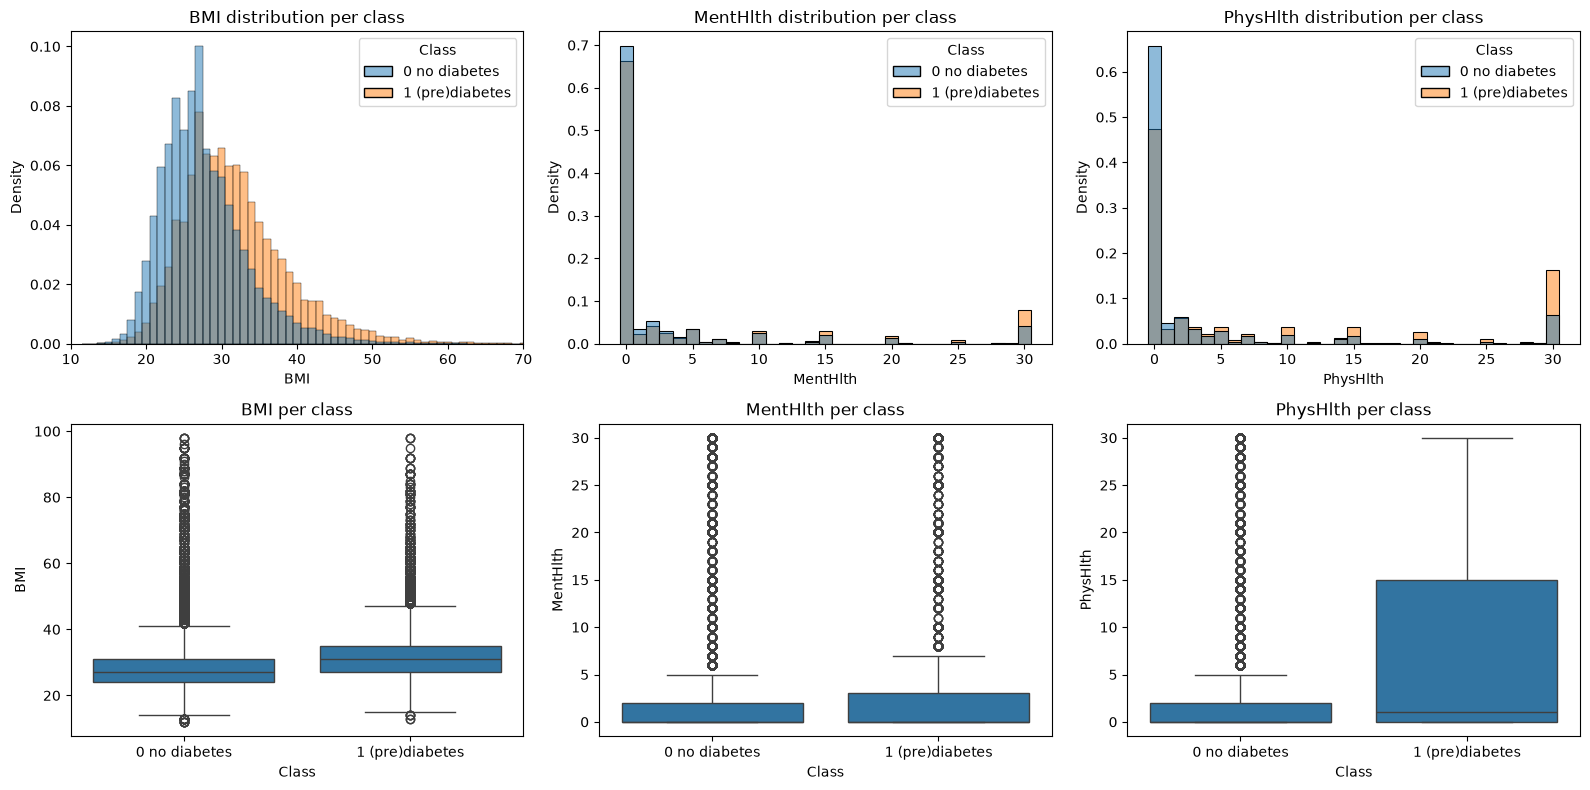

Diabetes_binary       0.0      1.0
BMI      count   218334.0  35346.0
         mean        27.8     31.9
         std          6.3      7.4
         min         12.0     13.0
         25%         24.0     27.0
         50%         27.0     31.0
         75%         31.0     35.0
         max         98.0     98.0
MentHlth count   218334.0  35346.0
         mean         3.0      4.5
         std          7.1      8.9
         min          0.0      0.0
         25%          0.0      0.0
         50%          0.0      0.0
         75%          2.0      3.0
         max         30.0     30.0
PhysHlth count   218334.0  35346.0
         mean         3.6      8.0
         std          8.1     11.3
         min          0.0      0.0
         25%          0.0      0.0
         50%          0.0      1.0
         75%          2.0     15.0
         max         30.0     30.0

In [9]:
# Distributions of BMI, MentHlth, PhysHlth, compared between the two target classes

base_rate = y.mean()  # 13.9%, the reference for every "proportion of class 1" below
plot_df = df.assign(Class=y.map({0: '0 no diabetes', 1: '1 (pre)diabetes'}))  # readable class names for the legends (X itself is not touched)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, col in enumerate(numerical):
    # stat='density' with common_norm=False: each class's histogram sums to 1 on its own, so class 1 isn't squashed by being ~6x smaller
    sns.histplot(data=plot_df, x=col, hue='Class', stat='density', common_norm=False, discrete=True, ax=axes[0, i])
    axes[0, i].set_title(f'{col} distribution per class')
    sns.boxplot(data=plot_df, x='Class', y=col, ax=axes[1, i])  # medians, quartiles and the tail per class
    axes[1, i].set_title(f'{col} per class')
axes[0, 0].set_xlim(10, 70)  # BMI tail above 70 is cut off for readability here, it is checked separately below
plt.tight_layout()
plt.show()

df.groupby(target)[numerical].describe().T.round(1)  # summary statistics per class

In [10]:
# The numbers behind the shapes

for col in numerical:
    print(f"{col}: skewness {df[col].skew():.2f}, share of zeros {(df[col] == 0).mean():.1%}, "
          f"most common values: {df[col].value_counts().head(7).index.astype(int).tolist()}")

print(f"\nPhysHlth counts for 25-30 days: {df['PhysHlth'].value_counts().sort_index().loc[25:30].astype(int).to_dict()}")  # how many answered each value near the top

# Does the proportion of class 1 change with the number of bad days?
days = [0, 1, 2, 5, 10, 15, 20, 30]
print(pd.DataFrame({
    'PhysHlth': df.groupby('PhysHlth')[target].mean().loc[days],
    'MentHlth': df.groupby('MentHlth')[target].mean().loc[days],
}, index=days).rename_axis('days').round(3).T)

BMI: skewness 2.12, share of zeros 0.0%, most common values: [27, 26, 24, 25, 28, 23, 29]
MentHlth: skewness 2.72, share of zeros 69.3%, most common values: [0, 2, 30, 5, 1, 3, 10]
PhysHlth: skewness 2.21, share of zeros 63.1%, most common values: [0, 30, 2, 1, 3, 5, 10]

PhysHlth counts for 25-30 days: {25.0: 1336, 26.0: 69, 27.0: 99, 28.0: 522, 29.0: 215, 30.0: 19400}
days         0      1      2      5      10     15     20     30
PhysHlth  0.105  0.104  0.137  0.172  0.231  0.263  0.280  0.295
MentHlth  0.133  0.095  0.116  0.135  0.167  0.186  0.197  0.229


**Question:** Do BMI and the number of bad health days differ between the two classes?

**Observed:**
- `BMI`: the whole class 1 distribution is shifted to the right. The median is `31` for class 1 against `27` for class 0, and the class 1 quartiles (27-35) lie above the class 0 quartiles (24-31). The two distributions still overlap heavily: the class 0 upper quartile (31) equals the class 1 median, so BMI on its own can't separate the classes.
- `PhysHlth`: most respondents in both classes report 0 bad physical days (63% overall), but the class 1 upper quartile is `15` days against `2` for class 0. The proportion of class 1 rises from 10.5% at 0 days to about 30% at 30 days.
- `MentHlth`: a much weaker difference. Both classes have a median of 0, and the share of class 1 only starts to rise above about 10 days.

**Unusual pattern:** the day counts are "heaped" on round numbers. 30 days was answered by `19,400` respondents against `215` for 29, and 5, 10, 15 and 20 are much more common than their neighbours. People seem to answer "about two weeks" or "the whole month" rather than an exact count, so the values are approximate. They are still counts of days according to the guide, so we keep treating them as numbers. All three features are also right-skewed (skewness 2.1-2.7), which we note but do not transform, to keep the first version simple, as in assignment 1.

**What we can conclude:** in this survey, respondents in class 1 tend to have a higher BMI and more days of poor physical health.

**What we cannot conclude:** that a high BMI or bad health days cause diabetes. For `PhysHlth` the order could just as well be the other way around, since diabetes itself can cause days of poor physical health. The survey is a single snapshot, so it cannot tell which came first.

### Unusual values: very high BMI

The guide gives the BMI range as 12-98. A BMI of 98 is extreme, so in the same way as the huge, cheap (partial) houses in assignment 1 we check whether the top of the range behaves like the rest of the data. If the very high values are real, we would expect them to have at least as much class 1 as the other high-BMI respondents.

In [11]:
# Unusual values: very high BMI

print(f"BMI 99th percentile: {df['BMI'].quantile(0.99):.0f}, rows above 70: {(df['BMI'] > 70).sum()} ({(df['BMI'] > 70).mean():.2%} of the data)")

bmi_bands = pd.cut(df['BMI'], [0, 18.5, 25, 30, 35, 40, 50, 70, 100])  # the usual BMI cut-offs, with the tail split at 50 and 70 to isolate the extreme values
print(df.groupby(bmi_bands, observed=True)[target].agg(['count', 'mean']).rename(columns={'mean': 'proportion class 1'}).round(3))

print("\nRows per BMI value above 70:")
print(df.loc[df['BMI'] > 70, 'BMI'].value_counts().sort_index().astype(int).to_dict())  # is the tail a smooth spread of values, or clumps?

BMI 99th percentile: 50, rows above 70: 584 (0.23% of the data)
               count  proportion class 1
BMI                                     
(0.0, 18.5]     3127               0.054
(18.5, 25.0]   86099               0.062
(25.0, 30.0]   91176               0.127
(30.0, 35.0]   44453               0.212
(35.0, 40.0]   17346               0.285
(40.0, 50.0]    9304               0.342
(50.0, 70.0]    1591               0.394
(70.0, 100.0]    584               0.130

Rows per BMI value above 70:
{71.0: 49, 72.0: 14, 73.0: 47, 74.0: 16, 75.0: 52, 76.0: 3, 77.0: 55, 78.0: 1, 79.0: 66, 80.0: 2, 81.0: 49, 82.0: 37, 83.0: 2, 84.0: 44, 85.0: 1, 86.0: 1, 87.0: 61, 88.0: 2, 89.0: 28, 90.0: 1, 91.0: 1, 92.0: 32, 95.0: 12, 96.0: 1, 98.0: 7}


The proportion of class 1 rises steadily with BMI, from about 6% for normal weight up to `39.4%` for BMI 50-70. Above 70 it falls back to `13.0%`, roughly the average for the whole dataset. The values above 70 also don't spread out smoothly: a few specific values (77, 79, 81, 84, 87, 92) have 28-66 rows each, while the values between them have 1-3. This doesn't look like a natural tail of real BMIs. A likely explanation is errors in the self-reported height and weight that the BMI is calculated from, but that is our guess, not something the guide says.

Decision: **keep** these 584 rows. In assignment 1 we removed the three "Partial" sales because the guide explained why they were odd (unfinished houses), and we could point at the exact rows. Here the guide lists 12-98 as the valid range, we cannot tell which of the high values are wrong and which are real, and 0.23% of the rows will have little influence on a model fitted on about 200,000 rows. We mention it as a limitation instead.

### Binary categorical features

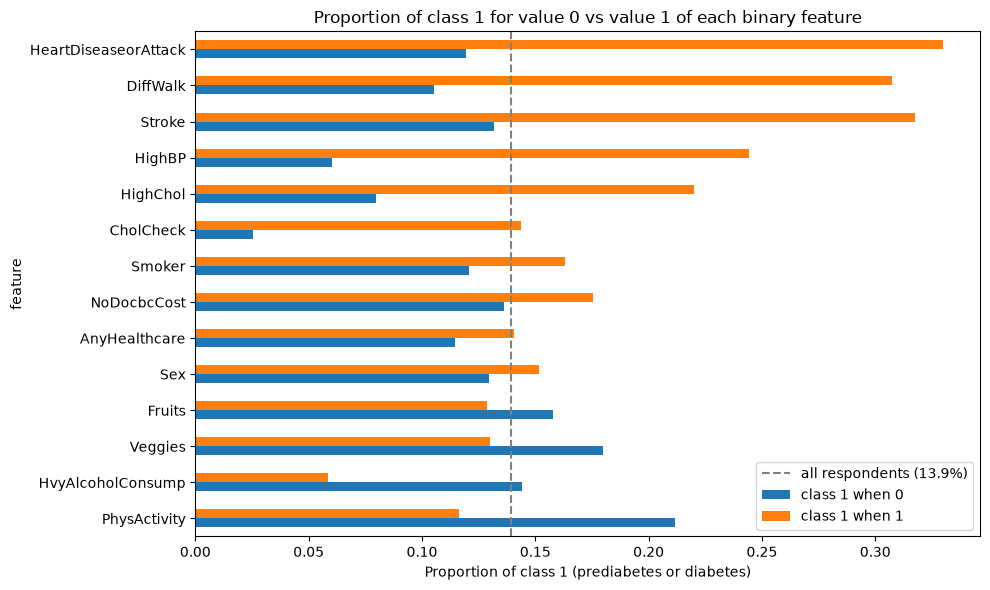

,share with value 1,n with value 1,class 1 when 0,class 1 when 1,difference
feature,,,,,
PhysActivity,0.757,191920,0.211,0.116,-0.095
HvyAlcoholConsump,0.056,14256,0.144,0.058,-0.086
Veggies,0.811,205841,0.180,0.130,-0.050
Fruits,0.634,160898,0.158,0.129,-0.029
Sex,0.440,111706,0.130,0.152,0.022
AnyHealthcare,0.951,241263,0.115,0.141,0.026
NoDocbcCost,0.084,21354,0.136,0.175,0.039
Smoker,0.443,112423,0.121,0.163,0.042
CholCheck,0.963,244210,0.025,0.144,0.118


In [12]:
# Counts/proportions and proportion of class 1 for each binary feature

rows = []
for col in binary:
    rate = df.groupby(col)[target].mean()  # proportion of class 1 when the feature is 0 and when it is 1
    rows.append({
        'feature': col,
        'share with value 1': df[col].mean(),  # for a 0/1 column the mean is the share of 1s
        'n with value 1': int(df[col].sum()),
        'class 1 when 0': rate[0],
        'class 1 when 1': rate[1],
        'difference': rate[1] - rate[0],  # > 0 means class 1 is more common in the "1" group
    })
binary_table = pd.DataFrame(rows).set_index('feature').sort_values('difference')

fig, ax = plt.subplots(figsize=(10, 6))
binary_table[['class 1 when 0', 'class 1 when 1']].plot.barh(ax=ax)
ax.axvline(base_rate, color='grey', linestyle='--', label=f'all respondents ({base_rate:.1%})')
ax.set_xlabel('Proportion of class 1 (prediabetes or diabetes)')
ax.set_title('Proportion of class 1 for value 0 vs value 1 of each binary feature')
ax.legend()
plt.tight_layout()
plt.show()

binary_table.round(3)

In [13]:
# Who is in the two surprising groups? Average age code and share with high blood pressure, per value

for col in ['CholCheck', 'HvyAlcoholConsump']:
    print(df.groupby(col)[['Age', 'HighBP']].mean().round(2), '\n')

            Age  HighBP
CholCheck              
0.0        6.63    0.18
1.0        8.09    0.44 

                    Age  HighBP
HvyAlcoholConsump              
0.0                8.06    0.43
1.0                7.60    0.42 



Note that for `Sex` the value 1 means male (0 = female), not "yes".

**Question:** Is the proportion of class 1 different between the two values of each binary feature?

**Observed:**
- **Largest differences:** `HeartDiseaseorAttack` (33.0% vs 12.0%), `DiffWalk` (30.7% vs 10.5%), `Stroke` (31.8% vs 13.2%), `HighBP` (24.4% vs 6.0%) and `HighChol` (22.0% vs 8.0%). `HighBP` and `HighChol` stand out because they are also common (about 43% answer yes), so the difference applies to a large part of the data. `Stroke` only applies to 4.1%.
- **In the other direction:** respondents who are physically active (11.6% vs 21.1%) or eat vegetables daily (13.0% vs 18.0%) have less class 1.
- **Small differences:** `Smoker`, `NoDocbcCost`, `AnyHealthcare`, `Fruits` and `Sex` (15.2% for men vs 13.0% for women) all differ by less than 5 percentage points. These appear to have little relationship with the target on their own.
- **Surprising directions:** heavy drinkers have *less* class 1 (5.8% vs 14.4%), and respondents who have *not* had their cholesterol checked have very little class 1 (2.5% vs 14.4%).
- **Lopsided features:** `CholCheck` (96.3% yes) and `AnyHealthcare` (95.1% yes) have almost everyone in one group, so the other group is small (about 9,000-12,000 rows).

**What we can conclude:** heart disease, stroke, difficulty walking, high blood pressure and high cholesterol are clearly associated with class 1 in this data.

**What we cannot conclude:** that heavy drinking protects against diabetes, or that cholesterol checks lead to it. Both results probably say more about *who* ends up in each group. A cholesterol check means contact with health care, which is also where diabetes gets diagnosed, and the respondents without a check are younger on average (age code 6.6 vs 8.1) and less often have high blood pressure (18% vs 44%), printed above. People diagnosed with diabetes may also have been told to drink less, and the survey only asks about current drinking. These explanations are guesses: the data shows the associations, not the reasons behind them.

### Ordered categorical features

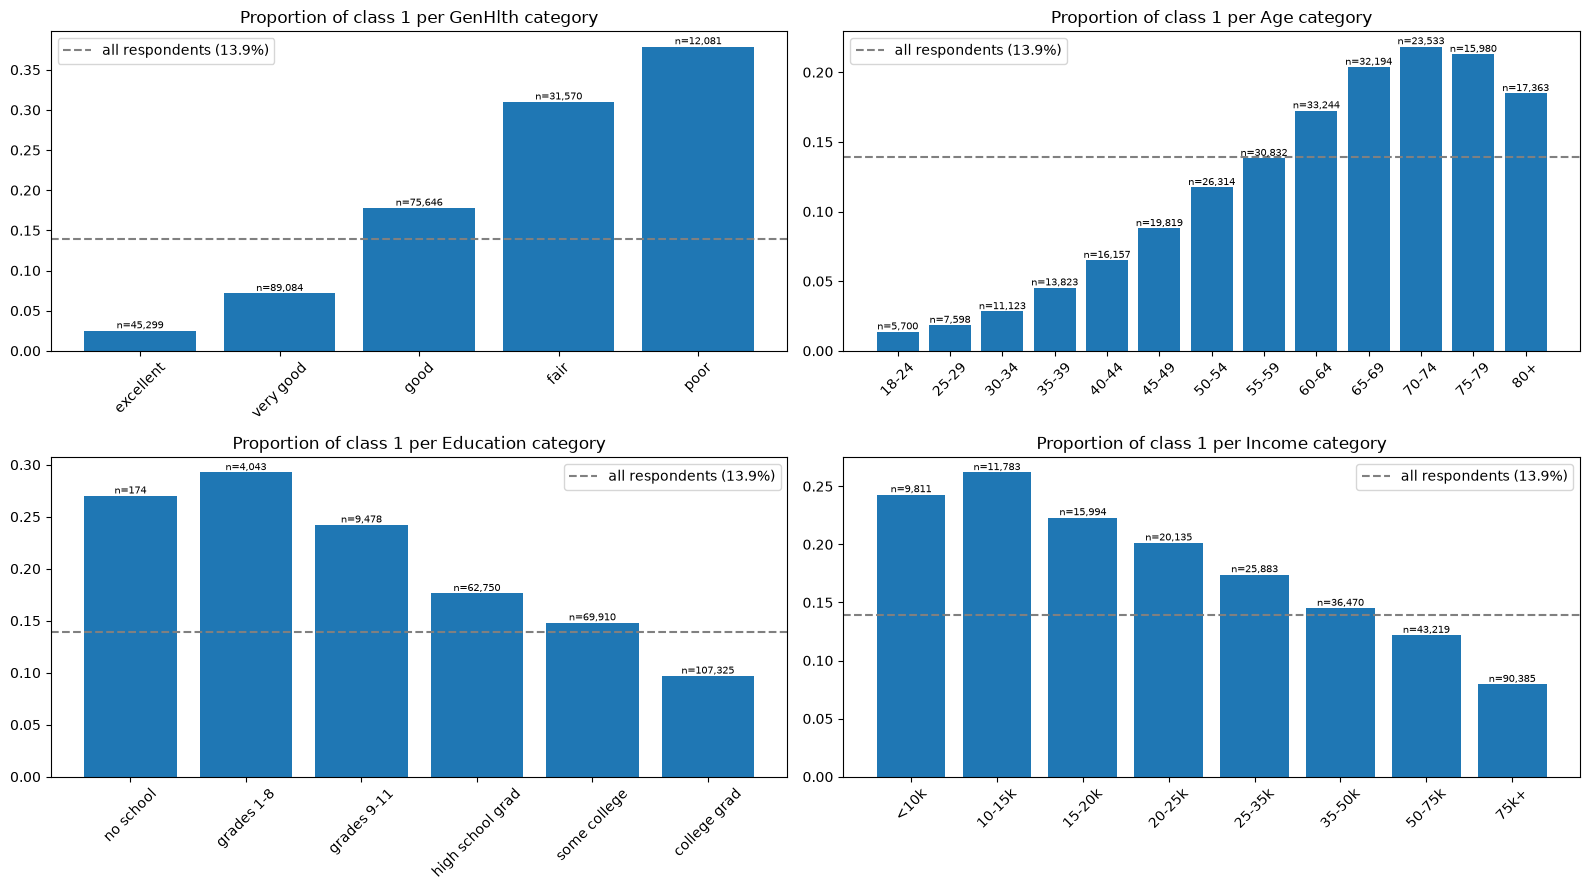


GenHlth
                    excellent  very good       good      fair       poor
count               45299.000  89084.000  75646.000  31570.00  12081.000
proportion class 1      0.025      0.072      0.178      0.31      0.379

Age
                       18-24     25-29      30-34      35-39      40-44      45-49      50-54      55-59      60-64      65-69      70-74      75-79        80+
count               5700.000  7598.000  11123.000  13823.000  16157.000  19819.000  26314.000  30832.000  33244.000  32194.000  23533.000  15980.000  17363.000
proportion class 1     0.014     0.018      0.028      0.045      0.065      0.088      0.117      0.138      0.172      0.204      0.218      0.213      0.185

Education
                    no school  grades 1-8  grades 9-11  high school grad  some college  college grad
count                  174.00    4043.000     9478.000         62750.000     69910.000    107325.000
proportion class 1       0.27       0.293        0.242             0.176  

In [14]:
# Proportion of class 1 across ordered categories (GenHlth, Age, Education, Income)

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, col in zip(axes.flat, ordinal):
    summary = df.groupby(col)[target].agg(['count', 'mean'])  # per category: number of respondents and proportion of class 1, in code order
    ax.bar(labels[col], summary['mean'])
    ax.axhline(base_rate, color='grey', linestyle='--', label=f'all respondents ({base_rate:.1%})')
    for x, (n, p) in enumerate(zip(summary['count'], summary['mean'])):
        ax.text(x, p, f'n={n:,}', ha='center', va='bottom', fontsize=7)  # show how many respondents each bar is based on
    ax.set_title(f'Proportion of class 1 per {col} category')
    ax.tick_params(axis='x', rotation=45)
    ax.legend()
plt.tight_layout()
plt.show()

for col in ordinal:  # the same numbers as tables
    summary = df.groupby(col)[target].agg(['count', 'mean']).rename(columns={'mean': 'proportion class 1'})
    summary.index = labels[col]
    print(f"\n{col}")
    print(summary.round(3).T.to_string())

**Question:** How does the proportion of class 1 change across the ordered categories?

**Observed:**
- `GenHlth` has the steepest change of all features: from `2.5%` class 1 for "excellent" to `37.9%` for "poor", rising at every step. (Higher code = worse health.)
- `Age`: rises steadily from `1.4%` (18-24) to `21.8%` (70-74), then levels off and drops slightly to `21.3%` (75-79) and `18.5%` (80+).
- `Income`: falls from about 25% in the lowest groups to `8.0%` for $75k+.
- `Education`: falls from about 29% (grades 1-8) to `9.7%` for college graduates. The "no school" group only has 174 respondents, so its 27% is uncertain.
- The distributions are uneven too: most respondents are 50-79 years old, have at least finished high school, and 36% are in the top income group.

**What we can conclude:** in this survey, class 1 is more common with worse self-rated health, higher age, lower income and less education, and the change goes mostly in one direction across the categories. This supports keeping the order of the categories when we encode them in Step 4. The bend at the top of `Age` is something a single straight-line effect will not capture.

**What we cannot conclude:** that low income or education causes diabetes. They are linked to many other things in the data (age, health care access, lifestyle), and the dip at 80+ could have several explanations (for example who survives to that age, or who answers a telephone survey) that this data cannot separate.

### Overlap between features

In assignment 1 we found that several of the strongest features carried overlapping information (garage cars and garage area, for example). Here `GenHlth`, `PhysHlth` and `DiffWalk` all seem to describe how healthy the respondent is, so we check how much they overlap:

In [15]:
# Overlap between features

print(df.groupby('GenHlth')[['PhysHlth', 'DiffWalk', 'HighBP', 'BMI']].mean().set_axis(labels['GenHlth'], axis=0).round(2))  # average of other health features per self-rated health level
print()
print(df[numerical].corr().round(2))  # a correlation is fine here, these three are real numbers

           PhysHlth  DiffWalk  HighBP    BMI
excellent      0.86      0.02    0.20  25.77
very good      1.53      0.06    0.36  27.64
good           3.39      0.17    0.51  29.51
fair          11.39      0.46    0.65  30.69
poor          23.52      0.75    0.69  30.57

           BMI  MentHlth  PhysHlth
BMI       1.00      0.09      0.12
MentHlth  0.09      1.00      0.35
PhysHlth  0.12      0.35      1.00


Respondents in "poor" health report on average `23.5` bad physical days and 75% have difficulty walking, against `0.9` days and 2% for "excellent". So `GenHlth`, `PhysHlth` and `DiffWalk` largely overlap. Among the numerical features, `PhysHlth` and `MentHlth` correlate 0.35, while `BMI` hardly correlates with either.

This matters when reading the model in Step 5: when features overlap, each coefficient only shows what that feature adds on top of the others, which can be very different from what the feature shows on its own in the EDA.

### Most informative findings

1. **Self-rated general health (`GenHlth`)** has the strongest relationship with the target: class 1 rises from 2.5% for "excellent" to 37.9% for "poor".
2. **High blood pressure and high cholesterol** are both common (about 43% of respondents) and roughly triple or quadruple the share of class 1 (24.4% vs 6.0% for `HighBP`).
3. **BMI** is shifted upwards for class 1 (median 31 vs 27), but the classes overlap heavily, and the values above 70 behave oddly (13.0% class 1, against 39.4% for BMI 50-70).
4. **Age** rises steadily up to 70-74 and then levels off, so its relationship is not a straight line all the way.
5. **Heavy alcohol consumption and cholesterol checks go in a surprising direction.** These are the clearest reminders that EDA shows associations in survey answers, not causes.

Features with little relationship on their own: `Fruits`, `Smoker`, `Sex`, `AnyHealthcare`, `NoDocbcCost` and `MentHlth`.

## Step 3 - Create TRAIN and TEST

> - Split X and y into TRAIN and TEST.
> - Use `stratify=y` so that TRAIN and TEST have approximately the same proportion of class 0 and class 1.
> - Keep TEST separate until evaluation. Do not balance or resample TEST.

In [ ]:
# Stratified split, then check class proportions in TRAIN and TEST

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=69, stratify=y  # 80/20, stratify=y keeps the class 1 share equal in both
)
print(f"TRAIN: {X_train.shape[0]} rows, TEST: {X_test.shape[0]} rows")

print(pd.DataFrame({  # the class proportions should be (almost) identical in all three
    'all data': y.value_counts(normalize=True),
    'TRAIN': y_train.value_counts(normalize=True),
    'TEST': y_test.value_counts(normalize=True),
}).round(4))

# TEST is set aside from here: no balancing or resampling, and nothing below is fitted on it

TRAIN: 202944 rows, TEST: 50736 rows
                 all data   TRAIN    TEST
Diabetes_binary                          
0                  0.8607  0.8607  0.8607
1                  0.1393  0.1393  0.1393


The class 1 share is 13.93% in TRAIN and TEST alike. Without `stratify=y` the shares would differ slightly by chance; with stratification the TEST set has the same imbalance as the real data, so the metrics in Step 6 reflect the situation the model would actually face. TEST is not balanced or resampled, since it has to stay a stand-in for unseen data.

## Step 4 - Prepare the features

> Preprocessing should reflect whether a feature is numerical, binary categorical, or ordered categorical. Briefly justify how each type is represented.
> - Use a Pipeline/ColumnTransformer where appropriate.
> - Anything learned from the data during preprocessing must be learned from TRAIN only and then applied to TEST.

| Type | Features | Representation | Why |
|---|---|---|---|
| Numerical | `BMI`, `MentHlth`, `PhysHlth` | `StandardScaler` (mean 0, std 1) | These are real amounts, so the distances between values mean something and they stay numbers. Scaling puts them on a comparable scale: logistic regression is fitted step by step and by default penalises large coefficients, so features on very different scales (BMI up to 98 vs 0/1 features) make the fit harder and the coefficients hard to compare. We check this in Step 5. |
| Binary | 14 yes/no features (incl. `Sex`) | Kept as 0/1 (`passthrough`) | They are already a 0/1 representation of two categories. One-hot encoding would only add a mirror column (`HighBP_0` = 1 - `HighBP_1`). Leaving them unscaled keeps the coefficient readable as "yes vs no". |
| Ordinal | `GenHlth`, `Age`, `Education`, `Income` | `OrdinalEncoder` with the category order from the guide, then `StandardScaler` | The categories have a meaningful order, and Step 2 showed that the share of class 1 mostly changes in one direction across them. Keeping the order gives one coefficient per feature. One-hot encoding would throw the order away and turn 4 columns into 32. The codes are already stored in the right order, so the encoder doesn't change it, but writing the order out from the guide documents it and makes the pipeline raise an error if a code outside the guide ever appears, instead of silently accepting it. |

The trade-off for the ordinal features: one coefficient means each step (e.g. from one age group to the next) is assumed to change the model's score (log-odds) by the same amount. The guide points out that the codes are ordered groups, not measured distances, and Step 2 showed that `Age` levels off at the top, so this is a simplification we accept and list as a limitation.

No imputation is needed (no missing values), and no rows are removed (Step 1 and Step 2 decisions). Everything that is learned from the data (means and standard deviations) sits inside the pipeline, so it is learned when the pipeline is fitted on TRAIN, and only applied to TEST.

In [17]:
# ColumnTransformer for numerical / binary / ordinal features

ordinal_categories = [[float(code) for code in range(1, len(labels[col]) + 1)] for col in ordinal]  # 1-5, 1-13, 1-6, 1-8, in the order given by the guide (floats, since the CSV stores 1.0, 2.0, ...)

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical),  # mean and std are learned when the pipeline is fitted on TRAIN
    ('ord', Pipeline([
        ('order', OrdinalEncoder(categories=ordinal_categories)),  # explicit order from the guide, errors on codes it doesn't know
        ('scale', StandardScaler()),  # then scaled like the numerical features
    ]), ordinal),
    ('bin', 'passthrough', binary),  # already 0/1, left as they are
])
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ord', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

## Step 5 - Train Logistic Regression

> Fit the complete Pipeline using TRAIN.
> - `model.predict(X_test)` for predicted classes.
> - `model.predict_proba(X_test)[:, 1]` for predicted probabilities for class 1.

In [18]:
# Pipeline: preprocessing + LogisticRegression, fit on TRAIN

model = Pipeline([
    ('prep', preprocessor),
    ('logreg', LogisticRegression()),  # default settings, no tuning, as in assignment 1
])
model.fit(X_train, y_train)  # both the preprocessing and the model are learned from TRAIN only

print(f"Fitted, the solver converged after {model.named_steps['logreg'].n_iter_[0]} iterations")

Fitted, the solver converged after 36 iterations


In [19]:
# Check: what did the preprocessing learn, and from where?

num_scaler = model.named_steps['prep'].named_transformers_['num']  # the fitted StandardScaler for the numerical features
pd.DataFrame({
    'mean learned by scaler': num_scaler.mean_,
    'TRAIN mean': X_train[numerical].mean().values,
    'TEST mean': X_test[numerical].mean().values,
}, index=numerical).round(4)

,mean learned by scaler,TRAIN mean,TEST mean
BMI,28.3937,28.3937,28.3371
MentHlth,3.1923,3.1923,3.1549
PhysHlth,4.2565,4.2565,4.1846


The means stored in the scaler are exactly the TRAIN means, not the TEST means, so the pipeline learned its preprocessing from TRAIN only. When we later call `predict` on TEST, the pipeline applies these TRAIN values to TEST.

In [20]:
# Predicted classes and class-1 probabilities on TEST

y_pred = model.predict(X_test)  # predicted class, 0 or 1
y_proba = model.predict_proba(X_test)[:, 1]  # predicted probability of class 1
print(f"Column order of predict_proba: {model.classes_}")  # [0 1] means column 1 is class 1, so [:, 1] is the right column

print(pd.DataFrame({'actual': y_test.values[:8], 'predicted': y_pred[:8], 'P(class 1)': y_proba[:8].round(3)}))  # the first few TEST rows

# predict() should be the same as cutting the probability at 0.5
print(f"\npredict() equals 'probability > 0.5' for every row: {(y_pred == (y_proba > 0.5)).all()}")
print(f"Rows with a probability of exactly 0.5: {(y_proba == 0.5).sum()}")  # if there were any, '> 0.5' and '>= 0.5' would disagree on them

Column order of predict_proba: [0 1]
   actual  predicted  P(class 1)
0       0          0       0.101
1       0          0       0.111
2       0          1       0.528
3       0          0       0.329
4       0          0       0.026
5       0          0       0.046
6       0          0       0.017
7       0          1       0.534

predict() equals 'probability > 0.5' for every row: True
Rows with a probability of exactly 0.5: 0


`predict()` is the same as using a threshold of 0.5 on the probabilities, and no row sits exactly on 0.5, so the 0.50 threshold in Step 7 will give exactly the same predictions as Step 6.

Most of the first rows get a low probability, which fits a target where only 13.9% are class 1.

We also want to check the claim from Step 4 that scaling matters here. In assignment 1, scaling made no difference to plain linear regression's predictions, since it is solved exactly. Logistic regression is solved step by step, so we fit the same model on the raw, unscaled values (still TRAIN only) and see if the solver complains:

In [21]:
# Is scaling actually needed? Same model, raw unscaled values, TRAIN only

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')  # record warnings instead of just printing them
    LogisticRegression().fit(X_train, y_train)
print([str(w.message).splitlines()[0] for w in caught] or 'No warnings')

['lbfgs failed to converge after 100 iteration(s) (status=1):']


On the raw values the solver does not converge within its default 100 iterations, while the scaled pipeline converged after 36. So scaling isn't just cosmetic here: without it, the default model doesn't finish fitting properly.

### What the model learned

In [22]:
# Coefficients of the fitted model, one per feature

coefficients = pd.Series(
    model.named_steps['logreg'].coef_[0],
    index=model.named_steps['prep'].get_feature_names_out(),  # num__ / ord__ / bin__ shows which part of the ColumnTransformer each comes from
).sort_values()
coefficients.round(3)

bin__HvyAlcoholConsump      -0.764
ord__Income                 -0.107
num__PhysHlth               -0.071
bin__Fruits                 -0.050
bin__PhysActivity           -0.046
bin__Veggies                -0.032
ord__Education              -0.032
num__MentHlth               -0.022
bin__Smoker                  0.001
bin__NoDocbcCost             0.026
bin__AnyHealthcare           0.123
bin__Stroke                  0.126
bin__DiffWalk                0.131
bin__HeartDiseaseorAttack    0.219
bin__Sex                     0.265
ord__Age                     0.373
num__BMI                     0.404
ord__GenHlth                 0.566
bin__HighChol                0.575
bin__HighBP                  0.760
bin__CholCheck               1.193
dtype: float64

A positive coefficient means a higher value pushes the predicted probability of class 1 up, with all the other features held fixed. For binary features it is the effect of "yes" vs "no"; for numerical and ordinal features it is the effect of one standard deviation.

- The largest positive coefficients are `CholCheck`, `HighBP`, `HighChol`, `GenHlth`, `BMI` and `Age`, which mostly matches the EDA.
- `HvyAlcoholConsump` has a large negative coefficient, the same surprising direction as in Step 2. As discussed there, this is not evidence that drinking protects against diabetes.
- `PhysHlth` gets a small *negative* coefficient, even though Step 2 showed more bad physical days going with more class 1. This is the overlap from Step 2: `GenHlth` and `DiffWalk` already carry most of that information, so the coefficient only shows what `PhysHlth` adds on top of them.

So coefficients should not be read as "how important a feature is" or as causes. `CholCheck` having the largest coefficient reflects the health-care-contact pattern from the EDA, not that a cholesterol check causes diabetes.

## Step 6 - Evaluate the model

> Evaluate on TEST using confusion matrix, accuracy, precision, recall and F1 score.
> Explain what a false positive and a false negative mean for this problem. Do not judge the model from accuracy alone.

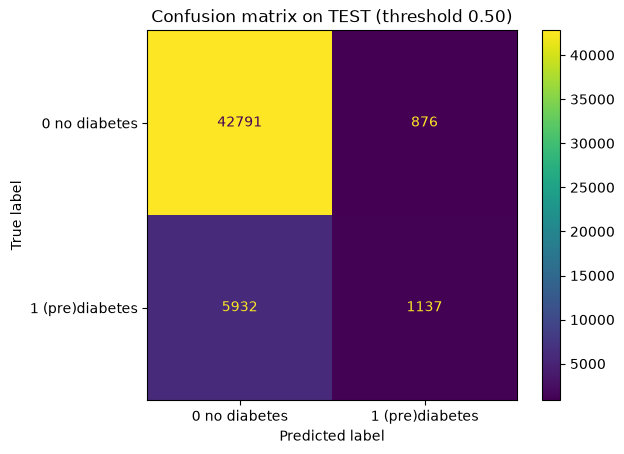

TN = 42791, FP = 876, FN = 5932, TP = 1137
Actual class 1 in TEST: 7069, of which found: 1137


In [23]:
# Confusion matrix

class_names = ['0 no diabetes', '1 (pre)diabetes']
cm = confusion_matrix(y_test, y_pred)  # rows = actual class, columns = predicted class
tn, fp, fn, tp = cm.ravel()  # sklearn's order: [[TN, FP], [FN, TP]]

ConfusionMatrixDisplay(cm, display_labels=class_names).plot(values_format='d')
plt.title('Confusion matrix on TEST (threshold 0.50)')
plt.show()

print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
print(f"Actual class 1 in TEST: {fn + tp}, of which found: {tp}")

In [24]:
# Accuracy, precision, recall, F1

def classification_metrics(y_true, y_hat):
    return {
        'Accuracy': accuracy_score(y_true, y_hat),  # share of all respondents classified correctly
        'Precision': precision_score(y_true, y_hat, zero_division=0),  # of those predicted class 1, share that really are (zero_division: the baseline never predicts 1, so this is 0/0)
        'Recall': recall_score(y_true, y_hat),  # of those really class 1, share that the model found
        'F1': f1_score(y_true, y_hat, zero_division=0),  # balance between precision and recall
    }

results = pd.DataFrame({
    'Always predict 0 (baseline), TEST': classification_metrics(y_test, np.zeros(len(y_test), dtype=int)),
    'Logistic Regression, TEST': classification_metrics(y_test, y_pred),
    'Logistic Regression, TRAIN': classification_metrics(y_train, model.predict(X_train)),  # only used to spot overfitting, not to judge the model
}).T
results.round(3)

,Accuracy,Precision,Recall,F1
"Always predict 0 (baseline), TEST",0.861,0.000,0.000,0.000
"Logistic Regression, TEST",0.866,0.565,0.161,0.250
"Logistic Regression, TRAIN",0.863,0.531,0.151,0.236


In the confusion matrix, the rows are the actual class and the columns the predicted class.

- **False positive (FP, `876`):** a respondent **without** diabetes whom the model predicts as prediabetes/diabetes. In practice: an unnecessary worry and a follow-up test that turns out negative.
- **False negative (FN, `5,932`):** a respondent **with** prediabetes or diabetes whom the model predicts as "no diabetes". In practice: a case that is missed. Since the motivation in the guide is early identification, so people can change lifestyle or start treatment, a false negative is arguably the more serious error here, while a false positive mostly costs a comparatively cheap extra test.

**Results:**
- **Accuracy `0.866`** looks good, but the baseline that always says "no diabetes" gets `0.861`. The model is only 0.5 percentage points better than not looking at the data at all, which is exactly why accuracy alone is not enough with an imbalanced target.
- **Precision `0.565`:** when the model says class 1, it is right a bit more than half the time.
- **Recall `0.161`:** the model only finds `1,137` of the `7,069` class 1 respondents in TEST and misses the other 84%. This is the real weakness, and accuracy hides it completely.
- **F1 `0.250`:** low, because it is pulled down by the low recall.
- **TRAIN vs TEST** are almost identical (accuracy 0.863 vs 0.866), so the model is not overfitting, unlike the decision tree in assignment 1. Its problem is the opposite: with these features and a 0.5 threshold, it rarely becomes confident enough to say "class 1".

### Where do the errors come from?

As in assignment 1, we look at where the errors are, here by comparing the predicted probabilities of the two actual classes:

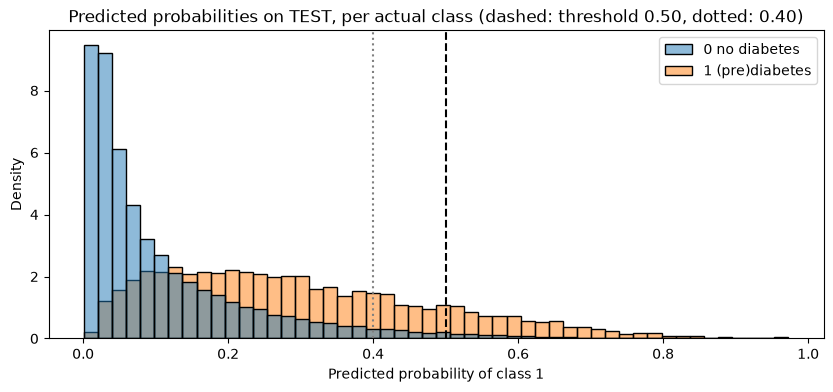

     count   mean    std    min    25%    50%    75%    max
0  43667.0  0.113  0.126  0.001  0.026  0.063  0.152  0.952
1   7069.0  0.299  0.185  0.004  0.149  0.266  0.417  0.973

Actual class 1 respondents with a predicted probability below 0.5: 83.9%


In [25]:
# Predicted probability of class 1, split by the actual class

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(x=y_proba, hue=y_test.map(dict(enumerate(class_names))).values, stat='density', common_norm=False, bins=50, ax=ax)  # each class normalised on its own, like in Step 2
ax.axvline(0.5, color='black', linestyle='--', label='threshold 0.50')
ax.axvline(0.4, color='grey', linestyle=':', label='threshold 0.40')
ax.set_xlabel('Predicted probability of class 1')
ax.set_title('Predicted probabilities on TEST, per actual class (dashed: threshold 0.50, dotted: 0.40)')
plt.show()

print(pd.Series(y_proba).groupby(y_test.values).describe().round(3))  # summary of the probabilities per actual class
print(f"\nActual class 1 respondents with a predicted probability below 0.5: {(y_proba[y_test == 1] < 0.5).mean():.1%}")

In [26]:
# Who are the missed class 1 respondents? False negatives vs true positives, on the strongest features from the EDA

is_class_1 = (y_test == 1).values
actual_1 = X_test[is_class_1].assign(outcome=np.where(y_pred[is_class_1] == 1, 'TP (found)', 'FN (missed)'))
actual_1.groupby('outcome')[['GenHlth', 'HighBP', 'HighChol', 'BMI', 'Age', 'DiffWalk', 'HeartDiseaseorAttack']].mean().round(2)

,GenHlth,HighBP,HighChol,BMI,Age,DiffWalk,HeartDiseaseorAttack
outcome,,,,,,,
FN (missed),3.11,0.71,0.63,30.53,9.30,0.29,0.17
TP (found),4.38,0.98,0.91,38.77,10.01,0.77,0.49


The median predicted probability for actual class 1 respondents is only `0.27`, and 84% of them get a probability below 0.5. The two histograms overlap a lot: many class 0 and class 1 respondents get similar probabilities, so no threshold can separate them cleanly.

The class 1 respondents the model *does* find are the most clear-cut cases: 98% have high blood pressure, their average BMI is 38.8, their average self-rated health is close to "fair" (4.4) and 77% have difficulty walking. The missed ones (false negatives) are much less extreme: 71% high blood pressure, BMI 30.5, self-rated health around "good" (3.1) and 29% difficulty walking. Their answers are closer to those of an average respondent, so with these features the model cannot tell many of them apart from class 0. This is a limit of the information in the features rather than a bug in the pipeline.

**Note:** We use TEST here only to understand the errors. Nothing from this is fed back into the model.

## Step 7 - Probability and threshold

> Compare thresholds 0.50 and 0.40. For each: confusion matrix, precision and recall.
> Explain what happened to false positives, false negatives, precision and recall, and what did NOT change when only the threshold changed.

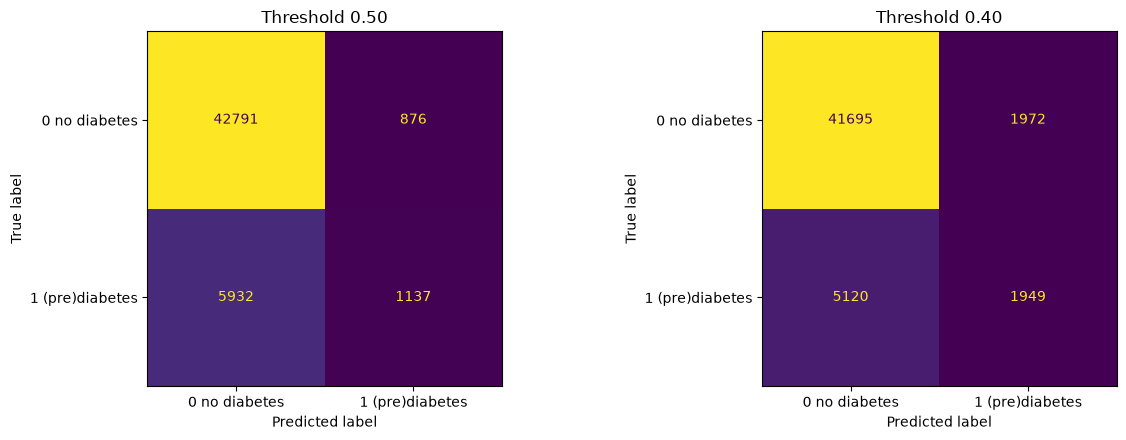

Threshold 0.50 gives the same predictions as model.predict(): True


In [27]:
# Apply thresholds 0.50 and 0.40 to the predicted probabilities

thresholds = [0.50, 0.40]
rows = []
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, threshold in zip(axes, thresholds):
    y_hat = (y_proba >= threshold).astype(int)  # same probabilities as before, only the cut-off changes
    cm_t = confusion_matrix(y_test, y_hat)
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel()
    ConfusionMatrixDisplay(cm_t, display_labels=class_names).plot(ax=ax, values_format='d', colorbar=False)
    ax.set_title(f'Threshold {threshold:.2f}')
    rows.append({
        'Threshold': threshold,
        **classification_metrics(y_test, y_hat),
        'False positives': fp_t,
        'False negatives': fn_t,
        'True positives': tp_t,
        'Predicted class 1': tp_t + fp_t,
        'Actual class 0 (TN + FP)': tn_t + fp_t,  # row sums of the confusion matrix, should not change
        'Actual class 1 (FN + TP)': fn_t + tp_t,
    })
plt.tight_layout()
plt.show()

print(f"Threshold 0.50 gives the same predictions as model.predict(): {((y_proba >= 0.5).astype(int) == y_pred).all()}")

In [28]:
# Threshold comparison table: Accuracy, Precision, Recall, F1, FP, FN

threshold_table = pd.DataFrame(rows).set_index('Threshold')
threshold_table.round(3)

,Accuracy,Precision,Recall,F1,False positives,False negatives,True positives,Predicted class 1,Actual class 0 (TN + FP),Actual class 1 (FN + TP)
Threshold,,,,,,,,,,
0.5,0.866,0.565,0.161,0.250,876,5932,1137,2013,43667,7069
0.4,0.860,0.497,0.276,0.355,1972,5120,1949,3921,43667,7069


In [29]:
# How much does each extra found case cost in false alarms?

change = threshold_table.loc[0.40] - threshold_table.loc[0.50]
print(f"Going from 0.50 to 0.40: {int(change['True positives'])} more class 1 found, {int(change['False positives'])} more false positives")
print(f"That is {change['False positives'] / change['True positives']:.2f} extra false alarms per extra case found")

Going from 0.50 to 0.40: 812 more class 1 found, 1096 more false positives
That is 1.35 extra false alarms per extra case found


**What changed when the threshold was lowered from 0.50 to 0.40:**
- More respondents are predicted as class 1 (`2,013` → `3,921`), because a lower probability is now enough.
- **False negatives went down** (`5,932` → `5,120`) and **false positives went up** (`876` → `1,972`). Each extra class 1 respondent found cost about 1.35 extra false alarms.
- **Recall went up** (`0.161` → `0.276`): the model now finds more of the actual class 1 respondents.
- **Precision went down** (`0.565` → `0.497`): among those flagged, a larger share are false alarms.
- **F1 went up** (`0.250` → `0.355`), since recall improved more than precision dropped. **Accuracy went slightly down** (`0.866` → `0.860`), and is now just *below* the always-0 baseline (0.861), even though the model finds 812 more cases. Another example of why accuracy alone is misleading here.

**What did NOT change:**
- The fitted model: same coefficients, same preprocessing, nothing was refitted. TRAIN was not used again.
- The predicted probabilities: the same `y_proba` was cut at a different place.
- The TEST data and its actual classes: both confusion matrices have `43,667` actual class 0 and `7,069` actual class 1 respondents (the row sums). Only the predicted columns moved.

Which threshold is "better" depends on how costly a missed case is compared to a false alarm. For screening, where a false positive leads to a cheap follow-up test and a false negative to a missed diagnosis, the lower threshold seems more reasonable. If we were to actually *choose* a threshold, we would have to do it on TRAIN (or a validation part of it) and not on TEST, otherwise the TEST results would become too optimistic, in the same way as choosing features based on TEST in assignment 1.

## Step 8 - Conclusion

> - Summarize the most important things learned from the EDA and the Logistic Regression results.
> - Give at least two limitations of this analysis.
> - Do not interpret an association as evidence that one feature causes diabetes.

**From the EDA:** class 1 (prediabetes or diabetes) is clearly more common among respondents with worse self-rated health, high blood pressure, high cholesterol, heart disease, difficulty walking, higher BMI and higher age, and among those with lower income and education. Several health features overlap (`GenHlth`, `PhysHlth`, `DiffWalk`). Some associations go in surprising directions (heavy drinking, cholesterol checks), which shows that these are patterns in survey answers, not causes.

**From the model:** Logistic Regression learned a pattern that mostly matches the EDA, but with the default threshold of 0.50 it only finds 16% of the class 1 respondents. Its accuracy (0.866) is barely above always predicting "no diabetes" (0.861). The model is not overfitting (TRAIN and TEST perform the same); the predicted probabilities of the two classes simply overlap a lot, and many class 1 respondents give answers that look like class 0. Lowering the threshold to 0.40 trades precision for recall (0.161 → 0.276) without changing the model itself.

**Limitations:**
1. **Survey data, a single snapshot.** All answers are self-reported and collected at one point in time, so we cannot tell what came first. Some associations (e.g. `HvyAlcoholConsump`, `CholCheck`, `PhysHlth`) may be consequences of a diabetes diagnosis or of contact with health care rather than risk factors. Nothing here shows causation.
2. **Class 1 merges prediabetes and diabetes.** The model cannot tell them apart, and the two groups may look quite different in the features.
3. **Ordinal features as one straight-line effect.** Encoding `Age`, `GenHlth`, `Education` and `Income` with one coefficient each assumes equal steps between categories. `Age` levels off at the top, which the model cannot capture.
4. **Data quality.** The BMI values above 70 behave unlike the rest of the high-BMI group, and the day counts are rounded by the respondents. We kept both, since we can't tell which values are wrong.
5. **Low recall at both thresholds, and thresholds not chosen from costs.** The two thresholds were given in the assignment. A real screening tool would need a threshold chosen from the costs of missed cases vs false alarms, chosen without using TEST.
6. **One random split**, as in assignment 1, so small differences in the metrics should not be over-read.